# NumCompute-Stream Demo

Read a CSV in chunks, train a decision tree through a streaming pipeline, and compare two retraining schedules on the same data.

## 1. Set up the stream

The synthetic data has two numeric features and one binary label. The label is 1 when the sum of the two original features is positive, and 0 otherwise. The same rule applies to every row. Some feature values are then set to NaN to demonstrate imputation.

In [1]:
%matplotlib inline

from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np

from numcompute.io import load_csv_chunks
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.preprocessing import SimpleImputer, StandardScaler
from numcompute_stream.stream import StreamTrainer
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.visualise import (
    compare_models,
    plot_metric_over_time,
    plot_predictions_vs_ground_truth,
)

chunk_size = 40
n_rows = 480 # number of rows
buffer_sizes = (80, 160)

rng = np.random.default_rng(42)
features = rng.normal(size=(n_rows, 2))
labels = (features.sum(axis=1) > 0).astype(int) # if two feature's sum is over 0, then label 1
features[rng.random(features.shape) < 0.06] = np.nan # make some nan values
csv_rows = np.column_stack((features, labels))

print(f"{n_rows} rows, {chunk_size} rows per chunk")
print(f"Missing feature values: {np.isnan(features).sum()}")

480 rows, 40 rows per chunk
Missing feature values: 51


## 2. Train and evaluate one chunk at a time

In [2]:
def make_trainer(buffer_size):
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="mean")),
        ("scaler", StandardScaler()),
        ("tree", DecisionTreeClassifier(max_depth=4, buffer_size=buffer_size)),
    ])
    return StreamTrainer(pipeline, labels=(0, 1), window_size=2 * chunk_size)


trainers = {size: make_trainer(size) for size in buffer_sizes} # make two trainers, buffer size 80 and 160

with TemporaryDirectory() as directory: # temp data file
    csv_path = Path(directory) / "stream_data.csv"
    np.savetxt(
        csv_path, csv_rows, delimiter=",", fmt=["%.8f", "%.8f", "%d"],
        header="feature_1,feature_2,label", comments="",
    )

    chunks = load_csv_chunks(csv_path, chunk_size=chunk_size, skip_header=1)
    for chunk_number, chunk in enumerate(chunks, start=1):
        X_chunk = chunk[:, :-1] # features
        y_chunk = chunk[:, -1].astype(int) # label
        if chunk_number == 1: # display sampel data
            print("First five rows loaded from the CSV:")
            print("feature_1  feature_2  label")
            for (first, second), label in zip(X_chunk[:5], y_chunk[:5]):
                print(f"{first:>9.3f}  {second:>9.3f}  {label:>5d}")

        for trainer in trainers.values():
            trainer.fit_chunk(X_chunk, y_chunk)

First five rows loaded from the CSV:
feature_1  feature_2  label
    0.305     -1.040      0
    0.750      0.941      1
      nan     -1.302      0
    0.128     -0.316      0
   -0.017     -0.853      0


## 3. Read the training log

A dash marks a chunk that could not be scored. The memory column reports peak traced allocations during the update. Cumulative metrics use the chunks each model could score, so the two histories start at different points.

In [3]:
primary = trainers[buffer_sizes[0]] # showing details of buffer size 80 trainer
print(f"Buffer size: {buffer_sizes[0]} rows")
print(f"{'Chunk':>5} {'Rows':>5} {'Accuracy':>9} {'Cumulative':>10} {'Refit':>5} {'Update ms':>10} {'Peak KiB':>9}")

for entry in primary.logs:
    accuracy = f"{entry['accuracy']:.2f}" if entry["evaluated"] else "-"
    cumulative = f"{entry['cumulative_accuracy']:.2f}" if entry["evaluated"] else "-"
    refit = "yes" if entry["retrained"] else "-"
    update_ms = entry["fit_seconds"] * 1000
    peak_kib = entry["peak_traced_bytes"] / 1024
    print(
        f"{entry['chunk']:>5} {entry['n_samples']:>5} {accuracy:>9} {cumulative:>10} "
        f"{refit:>5} {update_ms:>10.2f} {peak_kib:>9.1f}"
    )

# showing two trainers results
for size, trainer in trainers.items():
    metrics = trainer.metrics.result()
    refits = sum(entry["retrained"] for entry in trainer.logs)
    print(
        f"Buffer {size}: {refits} refits, {metrics['count']} scored rows, "
        f"accuracy {metrics['accuracy']:.3f}, F1 {metrics['f1']:.3f}, ROC AUC {metrics['auc']:.3f}"
    )

Buffer size: 80 rows
Chunk  Rows  Accuracy Cumulative Refit  Update ms  Peak KiB
    1    40         -          -     -       0.88       6.3
    2    40         -          -   yes       3.27      27.5
    3    40      0.90       0.90     -       0.32       6.4
    4    40      0.93       0.91   yes       5.68      32.6
    5    40      0.90       0.91     -       0.32       6.4
    6    40      0.95       0.92   yes       6.26      38.5
    7    40      0.93       0.92     -       0.31       6.4
    8    40      0.93       0.92   yes       4.37      32.5
    9    40      0.95       0.93     -       0.36       6.4
   10    40      0.95       0.93   yes       3.74      29.0
   11    40      0.85       0.92     -       0.31       6.4
   12    40      0.88       0.92   yes       5.13      29.8
Buffer 80: 6 refits, 400 scored rows, accuracy 0.915, F1 0.915, ROC AUC 0.923
Buffer 160: 3 refits, 320 scored rows, accuracy 0.928, F1 0.927, ROC AUC 0.948


## 4. Visualise the results

Compare per-chunk accuracy on chunks scored by both models. The final plot compares the labels predicted before the update with the true labels on the latest scored chunk.

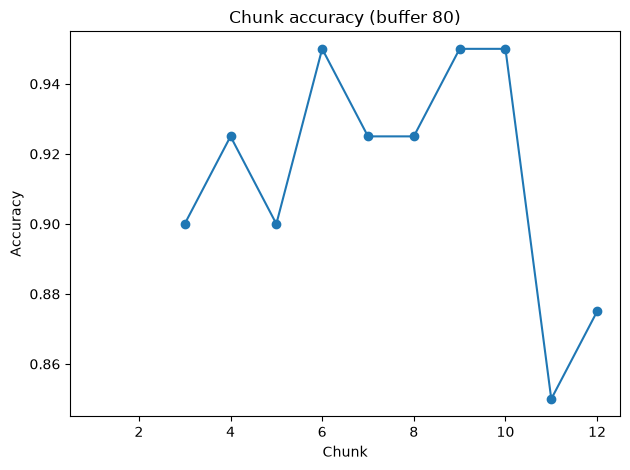

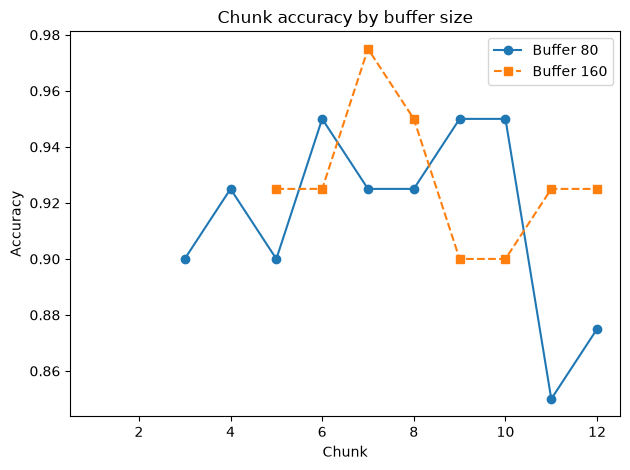

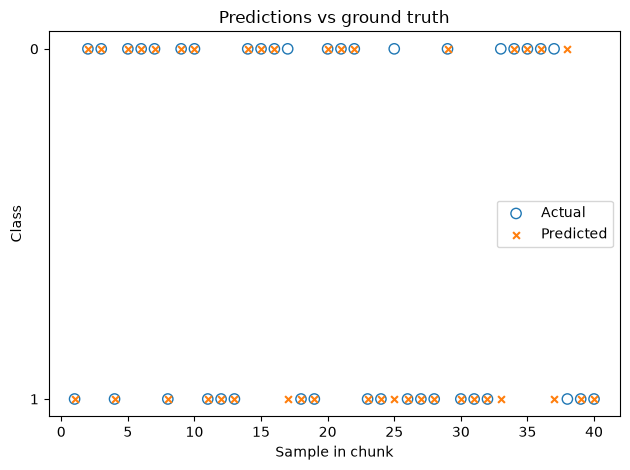

In [4]:
small_accuracy, large_accuracy = (
    [entry["accuracy"] for entry in trainers[size].logs]
    for size in buffer_sizes
)

# visualise buffer size 80 trainer's chunck accruacy
plot_metric_over_time(
    small_accuracy, f"Chunk accuracy (buffer {buffer_sizes[0]})", "Accuracy",
)

# visualise two trainers chuck accuracy
compare_models(
    small_accuracy, large_accuracy,
    [f"Buffer {size}" for size in buffer_sizes],
    title="Chunk accuracy by buffer size", ylabel="Accuracy",
)

# buffer size 80 trainer's last evaluation result
latest = primary.last_evaluation
plot_predictions_vs_ground_truth(latest["y_true"], latest["y_pred"])

plt.show()